In [1]:
# Librerie
from scipy import stats

# Per leggere i file
import gzip
import pickle

# Usual suspects
import matplotlib.pyplot as plt
import random
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Decomposition for Denoiseing
from statsmodels.tsa.seasonal import seasonal_decompose

# PAA e SAX
# non è la libreria del prof, ma la sua è datata e serve un miracolo per farla funzionare
from tslearn.piecewise import PiecewiseAggregateApproximation as PAA
from tslearn.piecewise import SymbolicAggregateApproximation as SAX

## Caricamento Dati
---
Il dataset viene definito direttamente ts. Qui ho anche verificato quali colonne cambiano all'interno di una time series e quali restano invece costanti (tipo id)

In [2]:
# Dataset
with gzip.open("CMI_timeseries_dataset.pkl.gz", "rb") as f:
    ts = pickle.load(f)

In [3]:
# Verifica della costanza delle variabili all'interno di ogni time series, e creazione di colonne_fisse
colonne_da_verificare = ts[0].columns.tolist()


# per ora sono tutte "Costanti"
costanti = {col: True for col in colonne_da_verificare}

for df in ts:
    for col in colonne_da_verificare:
        if col in df.columns:
            # Se la variabile è già stata marcata come "non costante", saltiamo il controllo
            if not costanti[col]:
                continue

            # Se troviamo una time series con più di un valore unico, la variabile non è costante
            if df[col].nunique(dropna=False) > 1:
                costanti[col] = False

# Print finale molto gagliardo
for col, is_constant in costanti.items():
    if is_constant:
        print(f"{col}: COSTANTE")
    else:
        print(f"{col}: VARIABILE")

colonne_fisse = ['weekday', 'quarter',
                 'relative_date_PCIAT', 'id', 'sii_binary']

X: VARIABILE
Y: VARIABILE
Z: VARIABILE
enmo: VARIABILE
anglez: VARIABILE
non-wear_flag: VARIABILE
light: VARIABILE
battery_voltage: VARIABILE
weekday: COSTANTE
quarter: COSTANTE
relative_date_PCIAT: COSTANTE
id: COSTANTE
sii_binary: COSTANTE


## Grafici Esplorativi
---
Gli stessi grafici li ripropongo anche in una sessione successiva dedicata alla visualizzazione di ogni step della pulizia, per vedere come i dati cambiano nel tempo.
In un secondo momento possiamo sicuramente eliminare questa parte, per ora sta qui all'inizio.
Le time series sono estratte casualmente (per ora senza seed) dall'universo

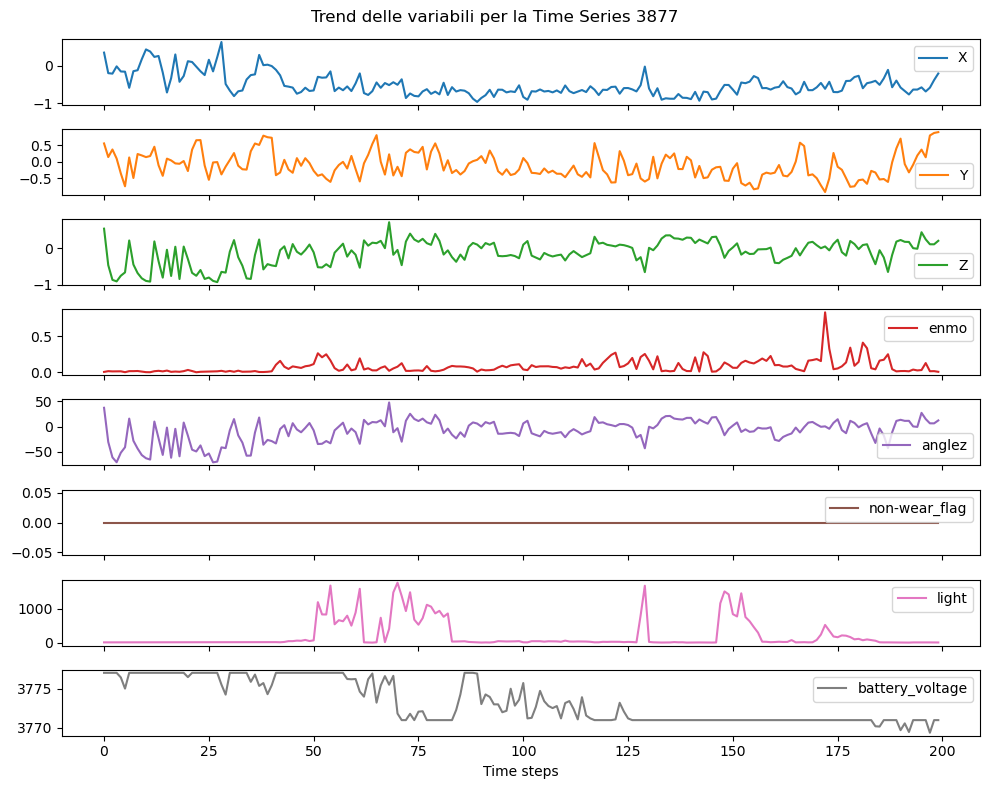

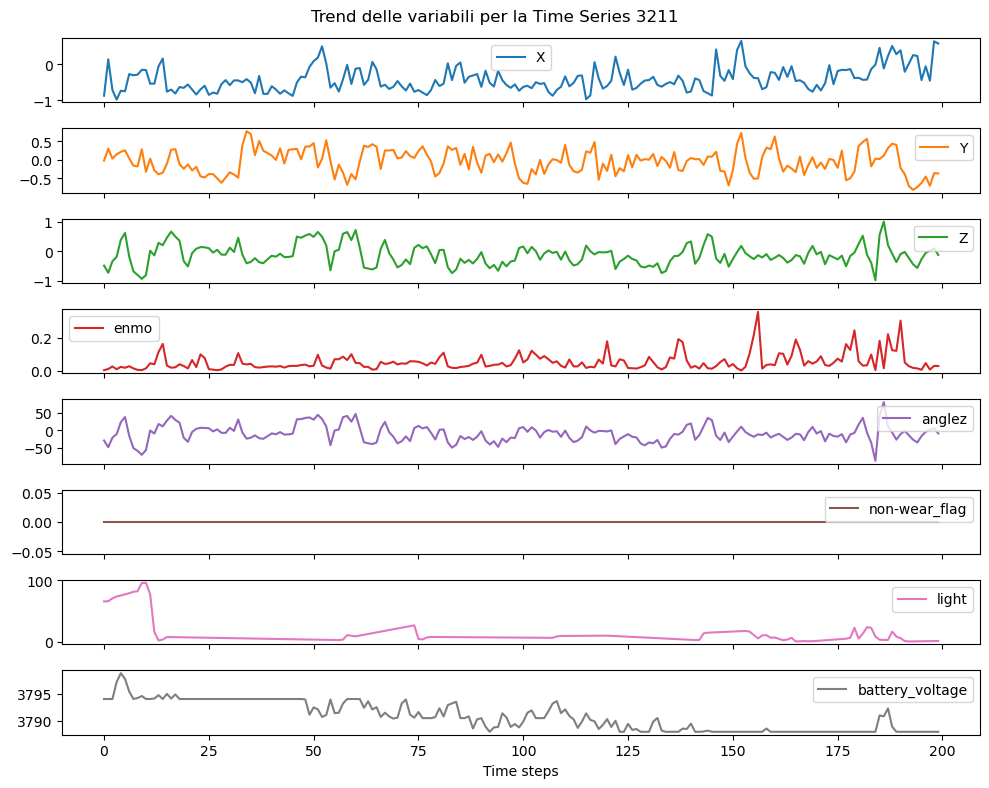

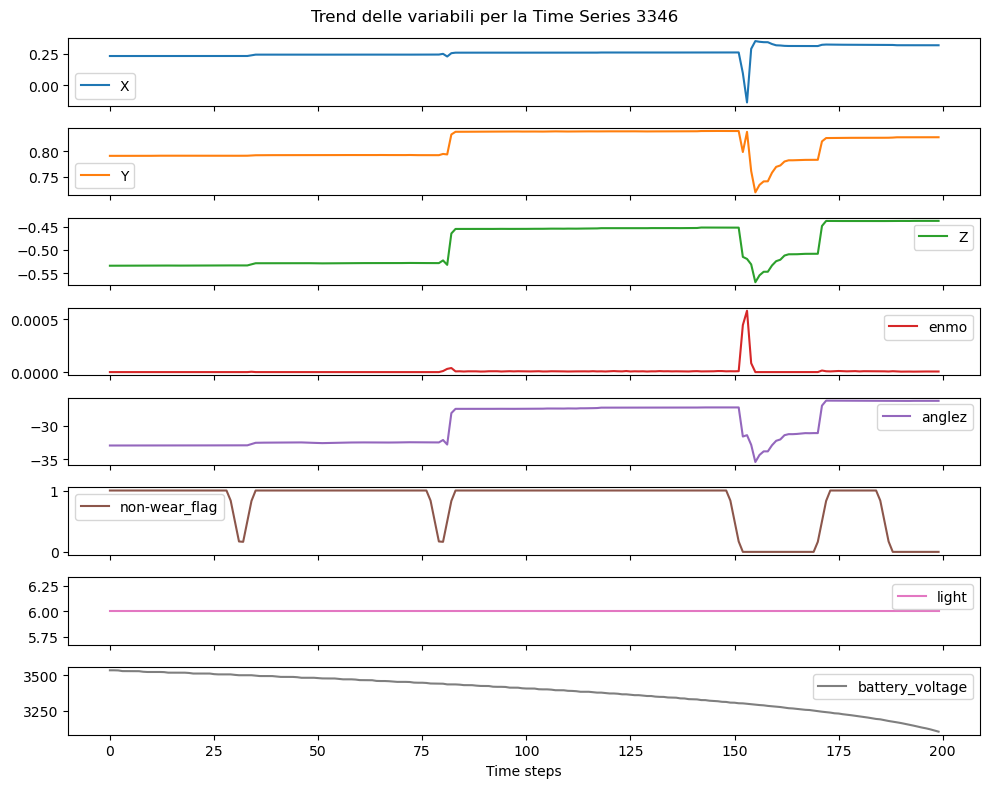

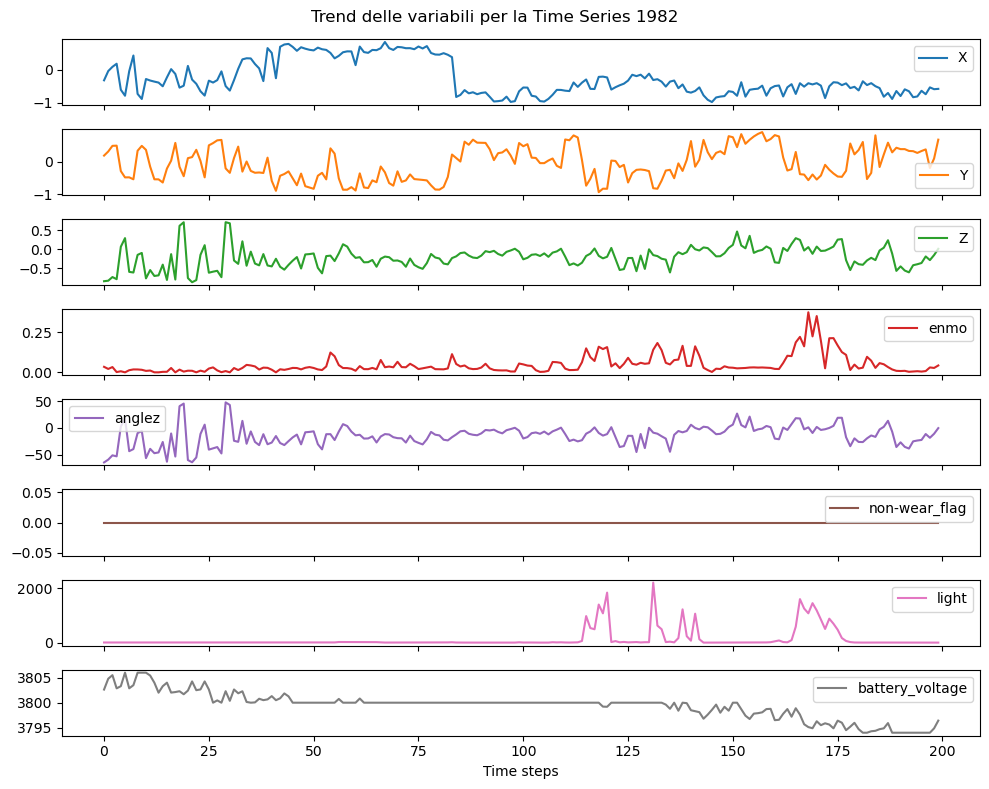

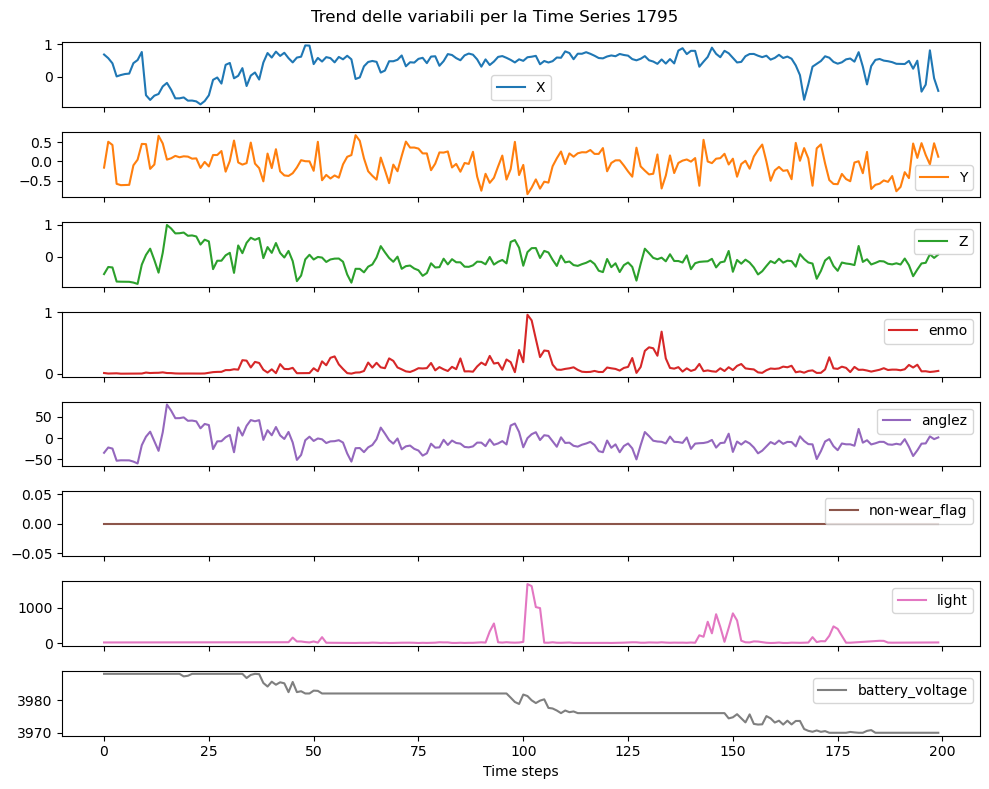

In [4]:
indice = random.sample(range(0, 4437), 5)

for i in indice:
    prova = ts[i]
    prova = prova.drop(colonne_fisse, axis=1)
    ax_array = prova.plot(
        kind='line',
        subplots=True,
        figsize=(10, 8),
        title=f"Trend delle variabili per la Time Series {i}",
        # Condivide l'asse X (i time steps 0-200) tra tutti i grafici
        sharex=True
    )

    # 5. Formattazione e visualizzazione
    plt.xlabel("Time steps")
    plt.tight_layout()  # Ottimizza gli spazi tra i grafici per evitare sovrapposizioni di testo
    plt.show()

## Missing Values
---
Ho controllato l'esistenza di missing values su tutto il dataset; sono assenti, meno roba da fare per noi :]

In [5]:
# Ricerca valori mancanti

# Calcola la somma dei NaN per ogni colonna in ciascuna time series.
# Il risultato è un nuovo DataFrame dove:
# - Le righe rappresentano le singole time series
# - Le colonne sono le variabili originali
# - I valori sono il numero di NaN presenti
missing_matrix = pd.DataFrame([df.isna().sum()
                              for df in ts])

# 1. Somma complessiva dei NaN per ogni variabile in tutto il dataset
totale_nan = missing_matrix.sum()

# 2. Conteggio di quante time series presentano almeno un NaN (> 0) per ogni variabile
ts_coinvolte = (missing_matrix > 0).sum()

# Visualizzazione dei risultati
totale_ts = len(ts)
print("--- Report Globale Missing Values Ottimizzato ---")

if totale_nan.sum() == 0:
    print("Il dataset è completo. Nessun missing value rilevato in alcuna variabile.")
else:
    for colonna in totale_nan.index:
        nan_count = totale_nan[colonna]

        # Filtra e stampa solo le variabili che hanno effettivamente valori mancanti
        if nan_count > 0:
            ts_count = ts_coinvolte[colonna]
            percentuale_ts = (ts_count / totale_ts) * 100

            print(f"Variabile: '{colonna}'")
            print(f"  - NaN totali: {nan_count}")
            print(
                f"  - Presenti in: {ts_count} time series ({percentuale_ts:.2f}% del dataset)\n")


# PS: Ho aggiunto degli NA a mano per testare il codice, e li ha trovati subito quindi funziona

--- Report Globale Missing Values Ottimizzato ---
Il dataset è completo. Nessun missing value rilevato in alcuna variabile.


## Outlier Detection con Filtro di Hampel
---
Applichiamo il filtro di Hampel basato su MAD (Median Absolute Deviation) su ogni serie temporale del dataset per identificare e gestire i valori anomali.
La formula utilizzata calcola la soglia sull'intera serie (non in una finestra mobile, in modo da avere una deviazione globale):
$$I = [median(X) - 3 * MAD ; median(X) + 3 * MAD]$$
$$MAD = median(|x_i - median(X)|)$$
Gli outlier verranno rimpiazzati con `NaN` (valori mancanti) per essere imputati successivamente.

In [6]:
# 1. Concatena la colonna battery_voltage di tutti i DataFrame della lista 'ts'
# Usiamo .dropna() per evitare errori dovuti a valori mancanti o outlier rimossi con Hampel
all_battery_values = pd.concat([df['battery_voltage'] for df in ts]).dropna()
# Statistiche descrittive numeriche
print("Statistiche descrittive globali:")
print(all_battery_values.describe())
conteggio = all_battery_values.value_counts().get(6000, 0)
print(conteggio)

Statistiche descrittive globali:
count    887400.000000
mean       3877.558594
std         170.317795
min        3099.083252
25%        3782.000000
50%        3864.616699
75%        4005.000000
max        6000.000000
Name: battery_voltage, dtype: float64
2


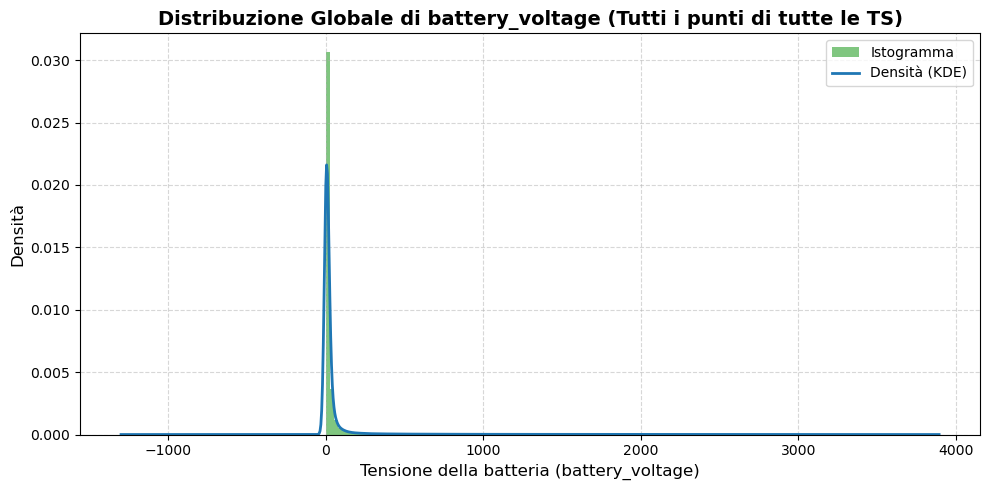

Statistiche descrittive globali:
count    887400.000000
mean         53.033752
std         208.232910
min           0.000000
25%           3.105195
50%           8.227631
75%          20.887396
max        2594.622070
Name: light, dtype: float64
0


In [7]:
all_light_values = pd.concat([df['light'] for df in ts]).dropna()
plt.figure(figsize=(10, 5))
# Istogramma
plt.hist(all_light_values, bins=100, density=True, alpha=0.6, color='#2ca02c', edgecolor='none', label='Istogramma')
# Stima della densità (KDE)
all_light_values.plot(kind='density', color='#1f77b4', linewidth=2, label='Densità (KDE)')

plt.title('Distribuzione Globale di battery_voltage (Tutti i punti di tutte le TS)', fontsize=14, fontweight='bold')
plt.xlabel('Tensione della batteria (battery_voltage)', fontsize=12)
plt.ylabel('Densità', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()
print("Statistiche descrittive globali:")
print(all_light_values.describe())
conteggio = all_battery_values.value_counts().get(2594.622070, 0)
print(conteggio)

In [8]:
#inutili ma li lascio che non si sa mai. provati tutti: 
def rileva_outliers_iqr(df, colonne_target, factor=1.5):
    outliers_mask = pd.DataFrame(False, index=df.index, columns=df.columns)
    bounds = {}
    
    for col in colonne_target:
        X = df[col]
        q25 = X.quantile(0.25)
        q75 = X.quantile(0.75)
        iqr = q75 - q25
        
        lower_bound = q25 - factor * iqr
        upper_bound = q75 + factor * iqr
        
        if col == 'light':
            lower_bound = max(0, lower_bound)
            
        bounds[col] = (lower_bound, upper_bound)
        outliers_mask[col] = (X < lower_bound) | (X > upper_bound)
        
    return outliers_mask, bounds

def rileva_outliers_grubbs(df, colonne_target, alpha=0.05):
    outliers_mask = pd.DataFrame(False, index=df.index, columns=df.columns)
    bounds = {}
    
    for col in colonne_target:
        X = df[col].copy()
        n = len(X.dropna())
        col_outliers = pd.Series(False, index=X.index)
        
        # Grubbs è iterativo: rimuove il max outlier finché non ce ne sono più
        while n > 2:
            mean = X.mean()
            std = X.std()
            if std == 0:
                break
                
            G_values = np.abs(X - mean) / std
            max_G = G_values.max()
            max_idx = G_values.idxmax()
            
            # Calcolo del valore critico di Grubbs
            t_crit = stats.t.ppf(1 - alpha / (2 * n), n - 2)
            G_crit = ((n - 1) / np.sqrt(n)) * np.sqrt(t_crit**2 / (n - 2 + t_crit**2))
            
            if max_G > G_crit:
                col_outliers[max_idx] = True
                X.loc[max_idx] = np.nan # Rimuovi e continua l'iterazione
                n -= 1
            else:
                break
                
        outliers_mask[col] = col_outliers
        # Grubbs non ha bound statici, ma possiamo salvare mean +- G_crit * std dell'ultimo step
        mean = X.mean()
        std = X.std()
        if n > 2 and std > 0:
            t_crit = stats.t.ppf(1 - alpha / (2 * n), n - 2)
            G_crit = ((n - 1) / np.sqrt(n)) * np.sqrt(t_crit**2 / (n - 2 + t_crit**2))
            lower_bound = mean - G_crit * std
            upper_bound = mean + G_crit * std
            if col == 'light':
                lower_bound = max(0, lower_bound)
            bounds[col] = (lower_bound, upper_bound)
        else:
            bounds[col] = (np.nan, np.nan)
            
    return outliers_mask, bounds

def rileva_outliers_hampel(df, colonne_target, n_sigmas=3):
    outliers_mask = pd.DataFrame(False, index=df.index, columns=df.columns)
    bounds = {}
    
    for col in colonne_target:
        X = df[col]
        median_X = X.median()
        MAD = np.median(np.abs(X - median_X))
        
        if MAD == 0:
            MAD = 1e-6
            
        lower_bound = median_X - n_sigmas * MAD
        upper_bound = median_X + n_sigmas * MAD
        
        if col == 'light':
            lower_bound = max(0, lower_bound)
            
        bounds[col] = (lower_bound, upper_bound)
        
        outliers_mask[col] = (X < lower_bound) | (X > upper_bound)
        
    return outliers_mask, bounds

In [9]:
# k=16 per considerae intervalli da 8 ore
k=16
def rileva_outliers_hampel_rolling(df, colonne_target, window_size=k, n_sigmas=3):
    outliers_mask = pd.DataFrame(False, index=df.index, columns=df.columns)
    bounds = {}
    
    for col in colonne_target:
        X = df[col]
        rolling_median = X.rolling(window=window_size, center=True, min_periods=1).median()
        rolling_abs_dev = (X - rolling_median).abs()
        rolling_mad = rolling_abs_dev.rolling(window=window_size, center=True, min_periods=1).median()
        rolling_mad = rolling_mad.replace(0, 1e-6)
        
        lower_bound = rolling_median - n_sigmas * rolling_mad
        upper_bound = rolling_median + n_sigmas * rolling_mad
        
        if col == 'light':
            lower_bound = lower_bound.clip(lower=0)
            
        bounds[col] = (lower_bound, upper_bound)
        outliers_mask[col] = (X < lower_bound) | (X > upper_bound)
        
    return outliers_mask, bounds

def visualizza_outliers(ts_list, index, colonne_hampel=None, colonne_iqr=None, colonne_hampel_rolling=None, colonne_grubbs=None, n_sigmas=3, factor=1.5, window_size=k, alpha=0.05):
    df = ts_list[index]
    if colonne_hampel is None: colonne_hampel = []
    if colonne_iqr is None: colonne_iqr = []
    if colonne_hampel_rolling is None: colonne_hampel_rolling = []
    if colonne_grubbs is None: colonne_grubbs = []
        
    mask_hampel, bounds_hampel = rileva_outliers_hampel(df, colonne_hampel, n_sigmas)
    mask_iqr, bounds_iqr = rileva_outliers_iqr(df, colonne_iqr, factor)
    mask_hampel_rolling, bounds_hampel_rolling = rileva_outliers_hampel_rolling(df, colonne_hampel_rolling, window_size, n_sigmas)
    mask_grubbs, bounds_grubbs = rileva_outliers_grubbs(df, colonne_grubbs, alpha)
    
    visualizzazioni = []
    for col in colonne_hampel: visualizzazioni.append((col, 'hampel'))
    for col in colonne_iqr: visualizzazioni.append((col, 'iqr'))
    for col in colonne_hampel_rolling: visualizzazioni.append((col, 'hampel_rolling'))
    for col in colonne_grubbs: visualizzazioni.append((col, 'grubbs'))
        
    if not visualizzazioni:
        print("Nessuna variabile specificata per la visualizzazione.")
        return
        
    num_cols = len(visualizzazioni)
    fig, axes = plt.subplots(num_cols, 1, figsize=(10, 2.5 * num_cols), sharex=True)
    if num_cols == 1: axes = [axes]
        
    for ax, (col, metodo) in zip(axes, visualizzazioni):
        ax.plot(df.index, df[col], label="Dati", color="blue", alpha=0.6)
        
        if metodo == 'hampel':
            mask = mask_hampel[col]
            lower, upper = bounds_hampel[col]
            label_metodo = f'Hampel (σ={n_sigmas})'
            color_outlier = "red"
        elif metodo == 'iqr':
            mask = mask_iqr[col]
            lower, upper = bounds_iqr[col]
            label_metodo = f'IQR (f={factor})'
            color_outlier = "purple"
        elif metodo == 'hampel_rolling':
            mask = mask_hampel_rolling[col]
            lower, upper = bounds_hampel_rolling[col]
            label_metodo = f'Hampel Rolling (w={window_size})'
            color_outlier = "green"
        else:
            mask = mask_grubbs[col]
            lower, upper = bounds_grubbs[col]
            label_metodo = f'Grubbs (α={alpha})'
            color_outlier = "cyan"
            
        outliers = df[col][mask]
        ax.scatter(outliers.index, outliers, color=color_outlier, label=f"Outlier ({label_metodo})", zorder=5)
        
        if isinstance(lower, pd.Series):
            ax.plot(df.index, lower, color='orange', linestyle='--', label='Lower Bound')
            ax.plot(df.index, upper, color='orange', linestyle='--', label='Upper Bound')
        elif lower is not None and not np.isnan(lower):
            ax.axhline(lower, color='orange', linestyle='--', label=f'Lower Bound ({lower:.2f})')
            ax.axhline(upper, color='orange', linestyle='--', label=f'Upper Bound ({upper:.2f})')
        
        ax.set_title(f"Variabile: {col} - Metodo: {label_metodo}")
        ax.legend(loc="upper right", bbox_to_anchor=(1.25, 1))
        
    plt.suptitle(f"Analisi Outliers - Time Series {index}", y=1.02, fontsize=14)
    plt.tight_layout()
    plt.show()


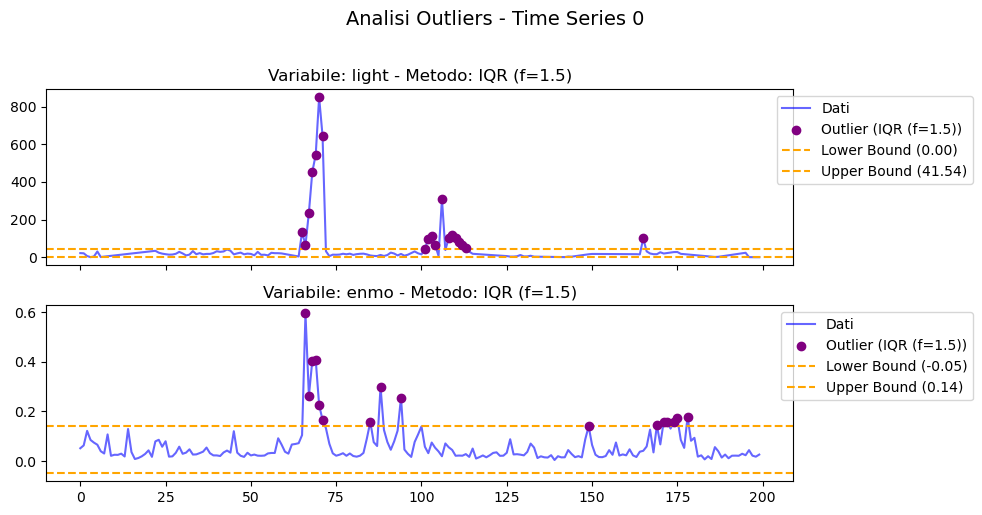

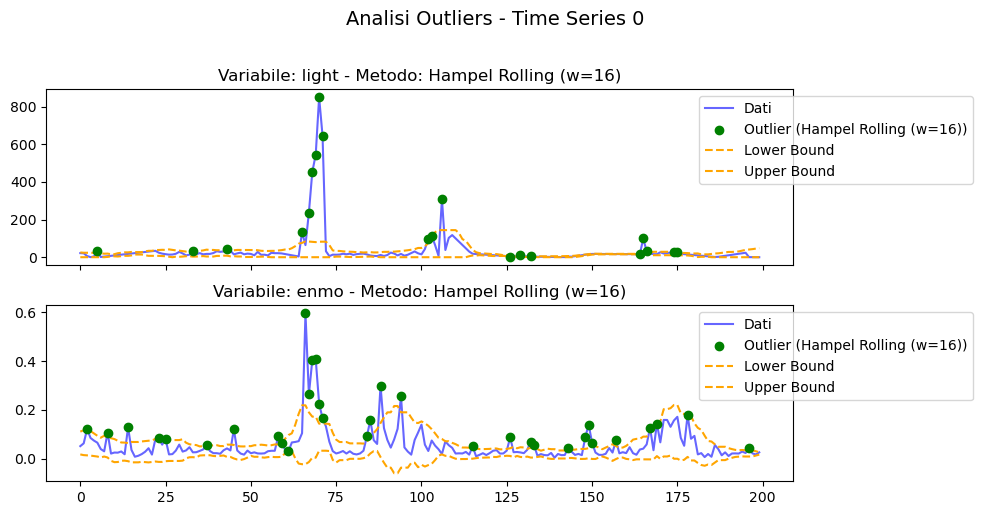

In [10]:
visualizza_outliers(ts, 0, colonne_iqr=['light','enmo'])
visualizza_outliers(ts, 0, colonne_hampel_rolling=['light','enmo'])

In [11]:
from tqdm.notebook import tqdm
import numpy as np

ts_pulito_outliers = []

# Definiamo le colonne da trattare escludendo le fisse, il flag di non usura e la batteria
colonne_escluse = set(colonne_fisse + ['non-wear_flag', 'battery_voltage'])
colonne_hampel = [col for col in ts[0].columns if col not in colonne_escluse]

for df in tqdm(ts, desc="Rilevamento e rimozione outliers"):
    df_copy = df.copy()
    
    # Rilevamento outliers
    outliers_mask, _ = rileva_outliers_hampel_rolling(df_copy, colonne_hampel)
    
    # Sostituzione con NaN per gli outliers
    for col in colonne_hampel:
        df_copy.loc[outliers_mask[col], col] = np.nan
        
    ts_pulito_outliers.append(df_copy)

# Il dataset ts_no_outliers contiene valori nulli al posto degli outlier
ts_no_outliers = ts_pulito_outliers


Rilevamento e rimozione outliers:   0%|          | 0/4437 [00:00<?, ?it/s]

In [12]:
from tqdm.notebook import tqdm
import numpy as np

# Creazione dataset alternativo: outliers + non-wear sostituiti con NaN
ts_outliers_and_non_wear = []

for df in tqdm(ts, desc="Rimozione outliers e non-wear"):
    df_copy = df.copy()
    
    outliers_mask, _ = rileva_outliers_hampel_rolling(df_copy, colonne_hampel)
    
    for col in colonne_hampel:
        # 1. Outliers a NaN
        df_copy.loc[outliers_mask[col], col] = np.nan
        
        # 2. Se non-wear_flag == 1, imposta a NaN per l'imputazione successiva
        if 'non-wear_flag' in df_copy.columns:
            df_copy.loc[df_copy['non-wear_flag'] == 1, col] = np.nan
            
    ts_outliers_and_non_wear.append(df_copy)

print(f"Creato dataset alternativo 'ts_outliers_and_non_wear' con {len(ts_outliers_and_non_wear)} serie temporali.")


Rimozione outliers e non-wear:   0%|          | 0/4437 [00:00<?, ?it/s]

Creato dataset alternativo 'ts_outliers_and_non_wear' con 4437 serie temporali.


In [13]:
from tqdm.notebook import tqdm

# 1. Imputazione mantenendo la struttura a lista di Time Series
ts_no_outliers_imputed = []
#ts_outliers_and_non_wear_imputed = []

colonne_da_imputare = [col for col in ts_no_outliers[0].columns if col not in colonne_fisse]

def imputa_lista_ts(ts_list, colonne):
    ts_imputed_list = []
    for df in tqdm(ts_list, desc="Imputazione dati mancanti"):
        df_imputed = df.copy()
        # Applichiamo l'interpolazione lineare sulla singola time series
        df_imputed[colonne] = df_imputed[colonne].interpolate(method='linear').ffill().bfill()
        ts_imputed_list.append(df_imputed)
    return ts_imputed_list

# Imputazione del primo dataset (solo outliers mancanti)
print("Imputazione ts_no_outliers...")
ts_no_outliers_imputed = imputa_lista_ts(ts_no_outliers, colonne_da_imputare)

# Imputazione del secondo dataset (outliers + non-wear mancanti)
print("Imputazione ts_outliers_and_non_wear...")
#ts_outliers_and_non_wear_imputed = imputa_lista_ts(ts_outliers_and_non_wear, colonne_da_imputare)

print(f"Imputazione completata. Struttura preservata: {len(ts_no_outliers_imputed)} DataFrames nella lista.")


Imputazione ts_no_outliers...


Imputazione dati mancanti:   0%|          | 0/4437 [00:00<?, ?it/s]

Imputazione ts_outliers_and_non_wear...
Imputazione completata. Struttura preservata: 4437 DataFrames nella lista.


In [14]:
# Controllo del valore massimo della variabile 'light' dopo l'imputazione e ricerca dell'indice della Time Series

# Per ts_no_outliers_imputed
max_val_1 = -1
max_idx_1 = -1
for i, df in enumerate(ts_no_outliers_imputed):
    current_max = df['light'].max()
    if current_max > max_val_1:
        max_val_1 = current_max
        max_idx_1 = i

print(f"Dataset 'ts_no_outliers_imputed': Valore max '{max_val_1}' trovato nella Time Series all'indice {max_idx_1}")


Dataset 'ts_no_outliers_imputed': Valore max '2594.00830078125' trovato nella Time Series all'indice 4072


In [ ]:
# Conteggio per il primo dataset (ts_no_outliers_imputed)
conteggio_df1 = sum((df['light'] > 101).sum() for df in ts_no_outliers_imputed)

print(f"Numero di valori 'light' > 101 nel primo dataset: {conteggio_df1}")
#print(f"Numero di valori 'light' > 100 nel secondo dataset: {conteggio_df2}")
ts_con_luce_alta = sum(1 for df in ts_no_outliers_imputed if (df['light'] > 101).any())
print(f"Numero di Time Series che hanno almeno un picco > 101: {ts_con_luce_alta}")


Numero di valori 'light' > 101 nel primo dataset: 40609
Numero di Time Series che hanno almeno un picco > 101: 1940


ts_con_luce_alta = sum(1 for df in ts_no_outliers_imputed if (df['light'] > 100).any())
print(f"Numero di Time Series che hanno almeno un picco > 100: {ts_con_luce_alta}")


Uniamo tutti i valori della colonna 'light' in un'unica serie pandas
tutti_i_valori_luce = pd.concat([df['light'] for df in ts_no_outliers_imputed], ignore_index=True)

Calcolo del 90esimo percentile (0.90)
percentile_90 = tutti_i_valori_luce.quantile(0.96)

Contiamo quanti valori superano rigorosamente quella soglia
valori_oltre_percentile = (tutti_i_valori_luce > percentile_90).sum()

print(f"Il 90esimo percentile della luce globale è: {percentile_90:.2f}")
print(f"Numero di valori totali di luce che superano il 90esimo percentile: {valori_oltre_percentile}")

Il 96esimo percentile della luce globale è: 101.84
Numero di valori totali di luce che superano il 96esimo percentile: 35496

gli si può dire che era 95 e non 96 per essere giustificabile in modo più semplice

In [ ]:
'''# Clipping della variabile 'light' a un massimo di 100 per eliminare i picchi residui dopo l'imputazione
for df in ts_no_outliers_imputed:
    if 'light' in df.columns:
        df.loc[df['light'] > 101, 'light'] = 101'''

#print("Valori di luce > 101 correttamente clippati (sostituiti con 101) in entrambi i dataset.")

for df in ts_no_outliers_imputed:
    if 'light' in df.columns:
        # Si usa log1p (log(1 + x)) per gestire in sicurezza eventuali valori pari a 0
        df['light'] = np.log1p(df['light'])

Valori di luce > 101 correttamente clippati (sostituiti con 101) in entrambi i dataset.


## Denoising 
---
Per il Denoiseing ho utilizzato sia Moving Average che la Decomposition, va scelto quale tenere.
- Moving Average è migliore IMO: la Decomposition sucks in this case.
Molto semplicemente non conosciamo il periodo delle rilevazioni (200 sono minuti, secondi, decine di secondi?), quindi quel parametro è completamente arbitrario. 
Inoltre, non sono sicuro che vi sia una vera stagionalità nel dataset, poichè non è chiaro in che contesto stiamo monitorando i bambini (credo che sia un intero giorno di monitoraggio, ma non ce scritto)

In [18]:
# colonne per entrambi i metodi. Per ora sta fuori, quando decidiamo il metodo torna dentro
colonne_no_noise = colonne_fisse + ['non-wear_flag']

In [ ]:
ts_denoised = []

for df in ts_no_outliers_imputed:
    df_pulito = df.copy()
    colonne_target = [
        col for col in df_pulito.columns if col not in colonne_no_noise]

    df_pulito[colonne_target] = df_pulito[colonne_target].rolling(
        window=5, min_periods=1).mean()

    ts_denoised.append(df_pulito)

In [20]:
periodo_stagionalita = 10  # questo parametro non so proprio come sceglierlo

ts_denoised_dc = []

for df in ts:
    df_pulito = df.copy()

    colonne_target = [
        col for col in df_pulito.columns if col not in colonne_no_noise]

    for col in colonne_target:
        decomposizione = seasonal_decompose(
            df_pulito[col],
            model='additive',
            period=periodo_stagionalita,
            extrapolate_trend='freq'
        )

        # Questa parte è un attimo diverso dalle slide. Nelle Slide, per fare il Denoise, si usa Y’ = Y - R; però, visto che sappiamo che
        # Y = T + S + R, allora si può scrivere Y’ = T + S
        df_pulito[col] = decomposizione.trend + decomposizione.seasonal

    ts_denoised_dc.append(df_pulito)

## Normalizzazione
---
Per la normalizzazione ho deciso di usare entrambi gli approcci: Standard e MinMax.
- Per le variabili di movimento ho usato standard instance-wise, in modo tale da scalare tutte le variabili mantenendo la FORMA (quindi se bambini hanno fatto movimenti simili ma con intensità diverse, l'informazione si mantiene).
- Per le variabili di luce e batteria ho usato minmax dataset-wise, cos' da portare tutto nella solita scala, mantenendo le differenze di intensità dei valori. Se si fa instancewise e il bambino è rimasto tutto il giorno chiuso in casa, ci sta che 0=buio, 1 = leggermente meno buio, e la cosa non trasla per un bambino che magari è stato in casa e poi è uscito. Facendo datasetwise, 0 = buio, 1 = luminoso a prescindere da cosa ha fatto lo specifico bambino

In [21]:
variabili_std = ['X', 'Y', 'Z', 'enmo', 'anglez']
variabili_minmax = ['light', 'battery_voltage']
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

# Calcolo dei min e max. Si concatenano tutti i valori delle 2 variabili (tra tutte le ts) e si trovano i minimi e massimi globali
dati_minmax_globali = pd.concat(
    [df[variabili_minmax] for df in ts_denoised], ignore_index=True)
minmax_scaler.fit(dati_minmax_globali)

ts_normalized = []

for df in ts_denoised:
    df_norm = df.copy()

    df_norm[variabili_std] = std_scaler.fit_transform(df_norm[variabili_std])

    df_norm[variabili_minmax] = minmax_scaler.transform(
        df_norm[variabili_minmax])

    ts_normalized.append(df_norm)

with gzip.open("ts_normalized.pkl.gz", "wb") as f:
    pickle.dump(ts_normalized, f)

## Approssimazione
---
Onestamente non so ancora se serve. Lo ho fatto ma magari non si usa nelle analisi. L'unica opzione viabile è PAA:
- Nella consegna abbiamo PAA o SAX (time-dependent approximations)
- Fourier non è solo scartato nella consegna del preprocessing, ma ho visto che nella classification bisogna fare K-nn con DTW, quindi ci servono le dipendenze temporali
- SAX, come si evince dal nome, sucks. Non vedo perchè mai vorremmo approssimare il dataset con delle lettere quando possiamo farlo con dei numeri 

In [22]:
# PAA

paa = PAA(n_segments=20)
ts_paa_array = paa.fit_transform(ts_normalized)

ts_transformed_paa = []

nomi_colonne = ts_normalized[0].columns

for matrice_ts in ts_paa_array:
    df_approssimato = pd.DataFrame(matrice_ts, columns=nomi_colonne)
    ts_transformed_paa.append(df_approssimato)

with gzip.open("ts_transformed_paa.pkl.gz", "wb") as f:
    pickle.dump(ts_transformed_paa, f)

In [23]:
# SAX
sax = SAX(n_segments=20, alphabet_size_avg=5)

# Trasformazione: l'output è un array numpy 3D: (n_ts, n_segments, n_features)
ts_sax_array = sax.fit_transform(ts_normalized)

# Riconversione in lista di DataFrame per preservare la struttura e la leggibilità
ts_transformed_sax = []
nomi_colonne = ts_normalized[0].columns

for matrice_ts in ts_sax_array:
    df_sax = pd.DataFrame(matrice_ts, columns=nomi_colonne)
    ts_transformed_sax.append(df_sax)

## Confronto Grafici
---

Grafici Iniziali


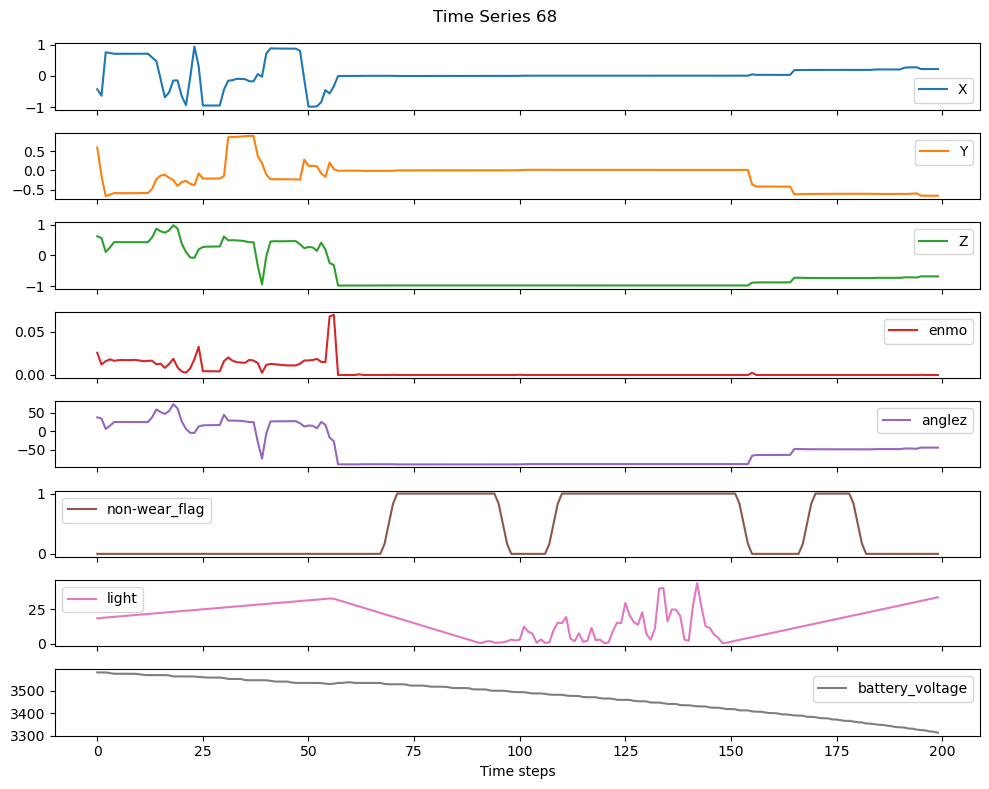

Grafici Outliers Imputati


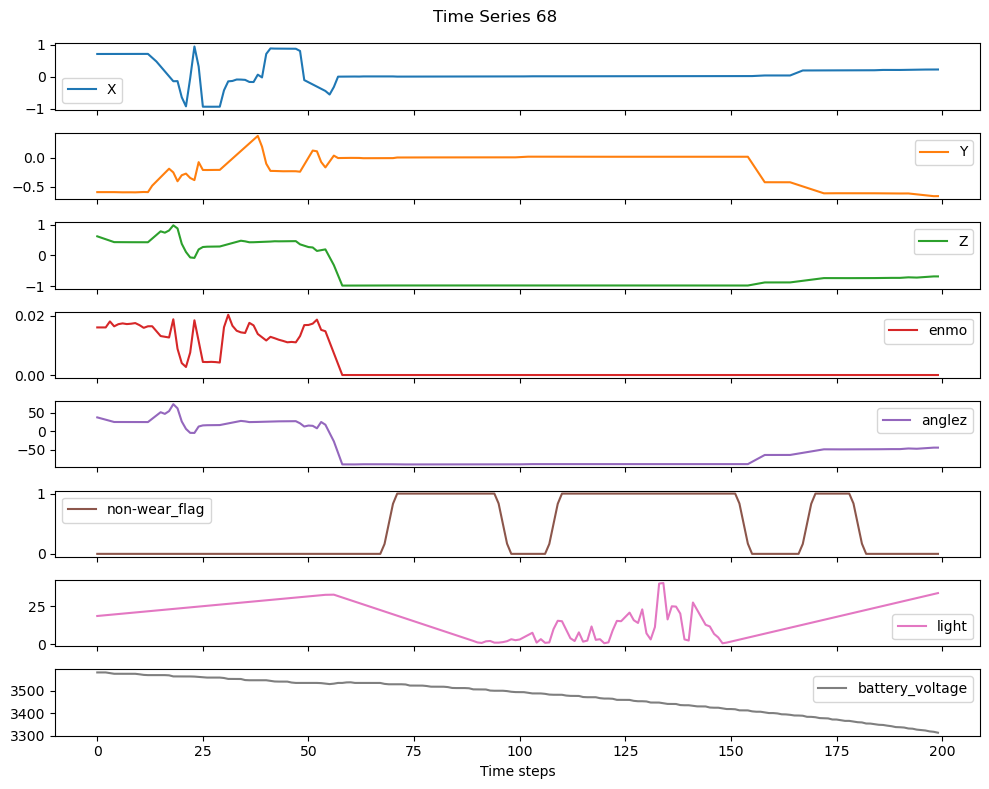

Grafici Outliers Imputati


NameError: name 'ts_outliers_and_non_wear_imputed' is not defined

In [ ]:
indice = random.sample(range(0, 4437), 1)

print("Grafici Iniziali")
for i in indice:
    prova = ts[i]
    prova = prova.drop(colonne_fisse, axis=1)
    ax_array = prova.plot(
        kind='line',
        subplots=True,
        figsize=(10, 8),
        title=f"Time Series {i}",
        sharex=True  # stessa asse x
    )

    plt.xlabel("Time steps")
    plt.tight_layout()
    plt.show()

print("Grafici Outliers Imputati")
for i in indice:
    prova = ts_no_outliers_imputed[i]
    prova = prova.drop(colonne_fisse, axis=1)
    ax_array = prova.plot(
        kind='line',
        subplots=True,
        figsize=(10, 8),
        title=f"Time Series {i}",
        sharex=True  # stessa asse x
    )

    plt.xlabel("Time steps")
    plt.tight_layout()
    plt.show()

print("Grafici Denoised")
for i in indice:
    prova = ts_denoised[i]
    prova = prova.drop(colonne_fisse, axis=1)
    ax_array = prova.plot(
        kind='line',
        subplots=True,
        figsize=(10, 8),
        title=f"Time Series {i}",
        sharex=True
    )

    plt.xlabel("Time steps")
    plt.tight_layout()
    plt.show()

print("Grafici Normalizzati")
for i in indice:
    prova = ts_normalized[i]
    prova = prova.drop(colonne_fisse, axis=1)
    ax_array = prova.plot(
        kind='line',
        subplots=True,
        figsize=(10, 8),
        title=f"Time Series {i}",
        sharex=True
    )

    plt.xlabel("Time steps")
    plt.tight_layout()
    plt.show()